# LinkShield AI — Notebook 02: Feature Engineering & Preprocessing

**Project:** LinkShield AI — AI Phishing & Malicious URL Detector for Banks  
**Phase:** Phase 1, Step 2 (Person 2 Deliverable)  
**Author:** Person 2 (Feature Engineering & Preprocessing)  
**Objective:** Validate raw URL data, perform conservative normalized deduplication, create reproducible stratified train/test partitions, conduct a comprehensive leakage audit, engineer 25 deterministic lexical features, build reusable scikit-learn preprocessing pipelines, and prepare a verified handover for Person 3.

> **Safety Protocol:** Zero network requests are made. All URLs are treated strictly as inert text strings.

In [1]:
import sys
import os
import json
import ipaddress
import math
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure src modules can be imported from project root
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))

from src.data_cleaning import (
    validate_schema,
    handle_whitespace,
    normalize_url,
    detect_duplicates,
    handle_duplicates,
    run_cleaning_pipeline
)
from src.url_features import URLFeatureExtractor, FEATURE_NAMES, SUSPICIOUS_KEYWORDS
from src.preprocessing import build_preprocessor, NUMERICAL_FEATURES, CATEGORICAL_FEATURES

print("Environment setup successful.")
print(f"Project root: {project_root}")
print(f"Total engineered features: {len(FEATURE_NAMES)}")

Environment setup successful.
Project root: C:\Users\Seif Badreldin\Downloads\LinkShield_AI
Total engineered features: 25


## 1. Project Context & Dataset Loading

Loading the raw dataset exported by Person 1 (`data/raw/person1_raw_labeled_urls.csv`).  
This dataset originates from the **PhiUSIIL Phishing URL Dataset (UCI ID 967)**, where Person 1 converted original labels (`1=legitimate, 0=phishing`) to the project convention:
- `is_phishing = 1`: Phishing URL
- `is_phishing = 0`: Legitimate URL

In [2]:
raw_csv_path = project_root / "data" / "raw" / "person1_raw_labeled_urls.csv"
assert raw_csv_path.exists(), f"Raw CSV not found at {raw_csv_path}"

raw_df = pd.read_csv(raw_csv_path)
print(f"Loaded raw records: {len(raw_df):,}")
print("Column structure:", list(raw_df.columns))
raw_df.head()

Loaded raw records: 235,795
Column structure: ['url', 'is_phishing']


,url,is_phishing
0,https://www.southbankmosaics.com,0
1,https://www.uni-mainz.de,0
2,https://www.voicefmradio.co.uk,0
3,https://www.sfnmjournal.com,0
4,https://www.rewildingargentina.org,0


## 2. Schema and Label Verification

Validating that:
1. The dataset contains exactly `url` and `is_phishing`.
2. No unexpected modelling columns exist.
3. Labels are strictly binary integers in `{0, 1}`.
4. All URL entries are non-null text strings.

In [3]:
schema_report = validate_schema(raw_df)
print("Schema Validation Report:")
print(json.dumps(schema_report, indent=2))

assert schema_report["expected_columns_found"], "Required columns missing!"
assert schema_report["labels_valid"], "Invalid labels detected!"
assert schema_report["urls_are_strings"], "Non-string URLs found!" 

Schema Validation Report:
{
  "columns_present": [
    "url",
    "is_phishing"
  ],
  "expected_columns_found": true,
  "unexpected_columns": [],
  "label_dtype": "int64",
  "labels_valid": true,
  "url_dtype": "str",
  "urls_are_strings": true,
  "missing_url_count": 0,
  "missing_label_count": 0,
  "invalid_label_count": 0,
  "non_string_url_count": 0,
  "total_rows": 235795
}


## 3. Cleaning Process & Normalized Duplicate Analysis

We perform conservative, RFC-compliant URL normalization **strictly for duplicate detection**:
- Strip surrounding whitespace.
- Lowercase scheme and hostname (RFC specifies hostnames are case-insensitive).
- Remove default ports (`:80` for HTTP, `:443` for HTTPS).
- **Preserve** case-sensitive paths, queries, and fragments.
- **Preserve** non-default ports.

In [4]:
dup_report = detect_duplicates(raw_df)
print("Duplicate Detection Summary:")
print(f"  Exact string duplicate rows: {dup_report['exact_duplicate_count']:,}")
print(f"  Normalized duplicate groups: {dup_report['normalized_dup_groups']:,}")
print(f"  Total rows in normalized groups: {dup_report['normalized_dup_total_rows']:,}")
print(f"  Conflicting-label groups: {dup_report['conflicting_label_groups']:,}")
print(f"  Same-label duplicate rows to remove: {dup_report['same_label_dup_rows']:,}")

Duplicate Detection Summary:
  Exact string duplicate rows: 425
  Normalized duplicate groups: 439
  Total rows in normalized groups: 878
  Conflicting-label groups: 0
  Same-label duplicate rows to remove: 439


In [5]:
clean_df, quarantined_df, full_cleaning_report = run_cleaning_pipeline(raw_df)

print(f"Raw record count:       {len(raw_df):,}")
print(f"Removed duplicates:     {full_cleaning_report['stages']['duplicate_handling']['same_label_dups_removed']:,}")
print(f"Quarantined conflicts:  {len(quarantined_df):,}")
print(f"Final clean records:    {len(clean_df):,}")
print("\nFinal Class Distribution:")
print(clean_df['is_phishing'].value_counts(normalize=True).apply(lambda p: f'{p:.2%}'))

Raw record count:       235,795
Removed duplicates:     439
Quarantined conflicts:  0
Final clean records:    235,356

Final Class Distribution:
is_phishing
0    57.30%
1    42.70%
Name: proportion, dtype: str


## 4. Stratified Train / Test Split

We perform an **80/20 stratified split** using `random_state=42` stratified on `is_phishing`.  
This ensures identical class distributions across both partitions before any scalers or encoders are fitted.

In [6]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    clean_df,
    test_size=0.20,
    random_state=42,
    stratify=clean_df["is_phishing"]
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train split size: {len(train_df):,} rows (80%)")
print(f"Test split size:  {len(test_df):,} rows (20%)")

split_table = pd.DataFrame({
    "Train Count": train_df["is_phishing"].value_counts(),
    "Train %": train_df["is_phishing"].value_counts(normalize=True).apply(lambda p: f"{p:.2%}"),
    "Test Count": test_df["is_phishing"].value_counts(),
    "Test %": test_df["is_phishing"].value_counts(normalize=True).apply(lambda p: f"{p:.2%}"),
}, index=[0, 1])
split_table.index = ["Legitimate (0)", "Phishing (1)"]
split_table

Train split size: 188,284 rows (80%)
Test split size:  47,072 rows (20%)


,Train Count,Train %,Test Count,Test %
Legitimate (0),107880,57.30%,26970,57.30%
Phishing (1),80404,42.70%,20102,42.70%


## 5. Leakage Audit

We audit the partitions against 5 critical leakage vectors:
1. **Exact URL leakage:** Any identical string in both sets.
2. **Normalized URL leakage:** Any functionally equivalent URL in both sets.
3. **Hostname overlap:** Distributional overlap between domains.
4. **Target leakage in features:** Verification that feature logic never accesses `is_phishing`.
5. **Preprocessing leakage:** Verification that scalers/encoders remain unfitted.

In [7]:
# 1. Exact URL Overlap
exact_leakage = set(train_df["url"]).intersection(set(test_df["url"]))

# 2. Normalized URL Overlap
from urllib.parse import urlparse
train_norm = set(train_df["url"].apply(normalize_url))
test_norm = set(test_df["url"].apply(normalize_url))
norm_leakage = train_norm.intersection(test_norm)

# 3. Hostname Overlap
def get_host(u):
    p = urlparse(u if "://" in u else "http://" + u)
    return (p.hostname or "").lower()

train_hosts = set(train_df["url"].apply(get_host)) - {""}
test_hosts = set(test_df["url"].apply(get_host)) - {""}
host_overlap = train_hosts.intersection(test_hosts)

test_rows_in_overlap = test_df["url"].apply(get_host).isin(host_overlap).sum()

print("Leakage Audit Results:")
print(f"  Exact URL overlap:      {len(exact_leakage)} (PASS)")
print(f"  Normalized URL overlap: {len(norm_leakage)} (PASS)")
print(f"  Unique train hosts:     {len(train_hosts):,}")
print(f"  Unique test hosts:      {len(test_hosts):,}")
print(f"  Overlapping hosts:      {len(host_overlap):,} ({len(host_overlap)/len(test_hosts):.2%} of test hosts)")
print(f"  Test rows with train hosts: {test_rows_in_overlap:,} / {len(test_df):,} ({test_rows_in_overlap/len(test_df):.2%})")

Leakage Audit Results:
  Exact URL overlap:      0 (PASS)
  Normalized URL overlap: 0 (PASS)
  Unique train hosts:     176,923
  Unique test hosts:      45,200
  Overlapping hosts:      2,046 (4.53% of test hosts)
  Test rows with train hosts: 3,745 / 47,072 (7.96%)


## 6. URL Lexical Feature Engineering

The `URLFeatureExtractor` transformer in `src/url_features.py` extracts **25 deterministic features** from raw URL strings without visiting destinations:
- **Structural features (16):** Lengths, character counts (dots, hyphens, slashes, `@`, digits, etc.).
- **Hostname features (4):** `num_subdomains`, `has_ip`, `has_https`, `has_www`.
- **Lexical/Statistical features (4):** `has_fragment`, `has_query`, `url_entropy`, `suspicious_keyword_count`.
- **Categorical feature (1):** `tld`.

In [8]:
sample_urls = pd.Series([
    "https://login-verify-account.bank-security.com/update?token=abc#section",
    "http://192.168.1.1/admin/login.php",
    "https://www.google.com/search?q=security",
    "http://suspicious-free-wallet.xyz/claim@user",
    "not-a-valid-url"
])

extractor = URLFeatureExtractor()
sample_features = extractor.transform(sample_urls)
print(f"Extracted shape: {sample_features.shape}")
sample_features

Extracted shape: (5, 25)


,url_length,domain_length,path_length,query_length,fragment_length,num_dots,num_hyphens,num_underscores,num_slashes,num_at_symbols,...,num_special_chars,num_subdomains,has_ip,has_https,has_www,has_fragment,has_query,url_entropy,suspicious_keyword_count,tld
0,71,38,7,9,7,2,3,0,3,0,...,12,1,0,1,0,1,1,4.501723,5,com
1,34,11,16,0,0,4,0,0,4,0,...,9,0,1,0,0,0,0,4.006437,1,
2,40,14,7,10,0,2,0,0,3,0,...,8,1,0,1,1,0,1,4.289823,0,com
3,44,26,11,0,0,1,2,0,3,1,...,8,0,0,0,0,0,0,4.328194,1,xyz
4,15,15,0,0,0,0,3,0,0,0,...,3,0,0,0,0,0,0,3.323231,0,


## 7. Feature Distributions & Descriptive Analysis

To verify feature distributions across classes, we extract features from a stratified sample (5,000 URLs) and compare distributions.

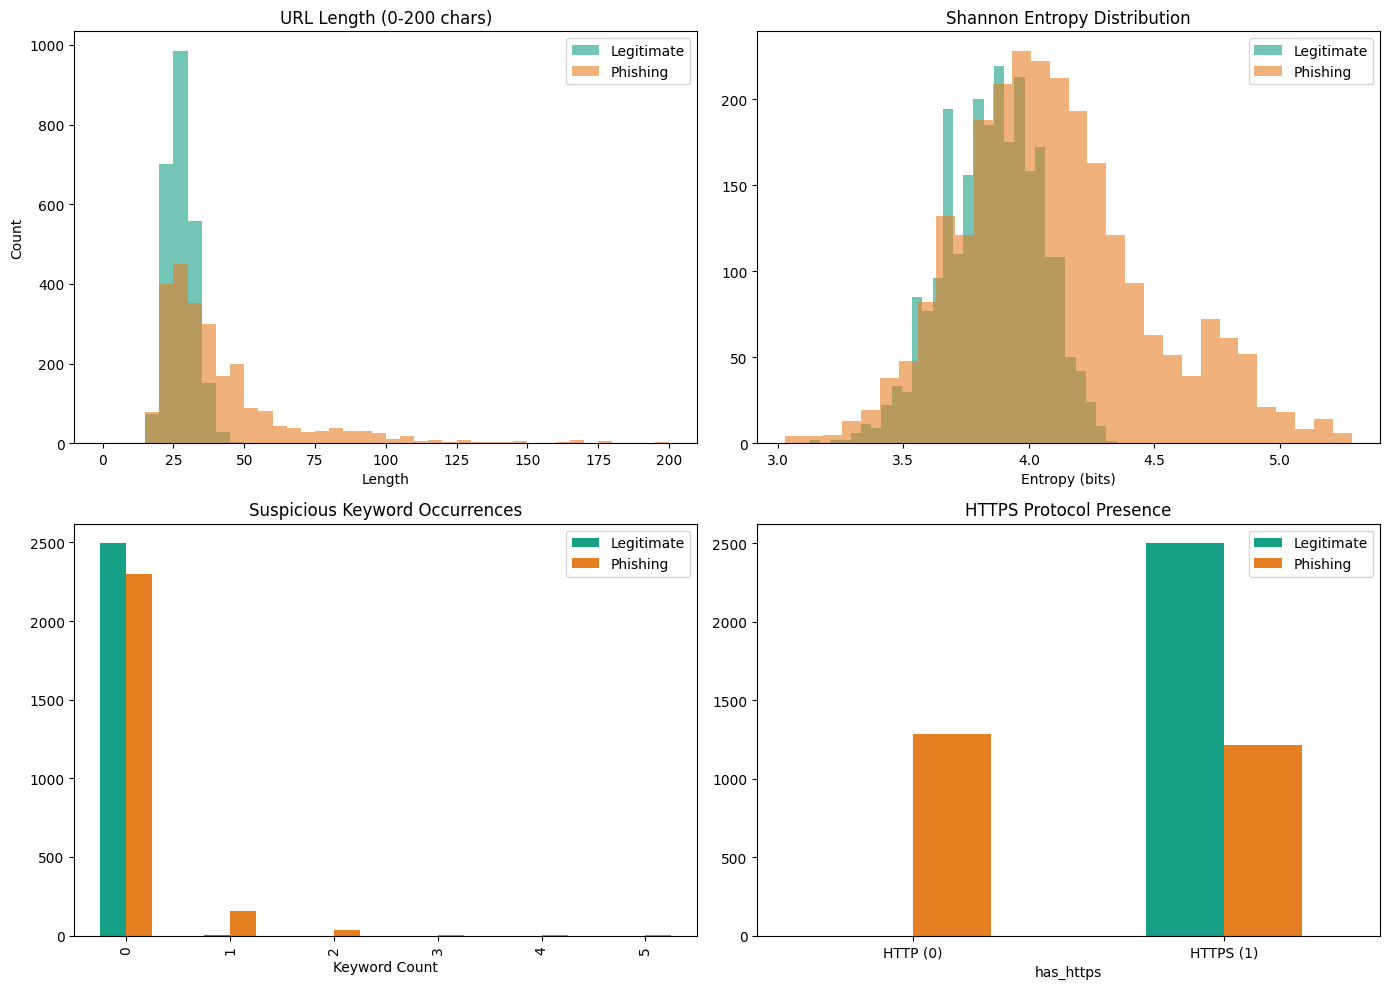

In [9]:
# Extract features on sample of 5,000 train URLs for analysis
sample_legit = train_df[train_df["is_phishing"] == 0].sample(2500, random_state=42)
sample_phish = train_df[train_df["is_phishing"] == 1].sample(2500, random_state=42)
sample_train = pd.concat([sample_legit, sample_phish]).sample(frac=1.0, random_state=42).reset_index(drop=True)

sample_feats = extractor.transform(sample_train["url"])
sample_feats["is_phishing"] = sample_train["is_phishing"].values

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. URL Length Distribution
axes[0, 0].hist(sample_feats[sample_feats["is_phishing"] == 0]["url_length"], bins=40, range=(0, 200), alpha=0.6, label="Legitimate", color="#16A085")
axes[0, 0].hist(sample_feats[sample_feats["is_phishing"] == 1]["url_length"], bins=40, range=(0, 200), alpha=0.6, label="Phishing", color="#E67E22")
axes[0, 0].set_title("URL Length (0-200 chars)")
axes[0, 0].set_xlabel("Length")
axes[0, 0].set_ylabel("Count")
axes[0, 0].legend()

# 2. Shannon Entropy
axes[0, 1].hist(sample_feats[sample_feats["is_phishing"] == 0]["url_entropy"], bins=30, alpha=0.6, label="Legitimate", color="#16A085")
axes[0, 1].hist(sample_feats[sample_feats["is_phishing"] == 1]["url_entropy"], bins=30, alpha=0.6, label="Phishing", color="#E67E22")
axes[0, 1].set_title("Shannon Entropy Distribution")
axes[0, 1].set_xlabel("Entropy (bits)")
axes[0, 1].legend()

# 3. Suspicious Keyword Count
kw_counts = sample_feats.groupby(["suspicious_keyword_count", "is_phishing"]).size().unstack(fill_value=0)
kw_counts.plot(kind="bar", ax=axes[1, 0], color=["#16A085", "#E67E22"])
axes[1, 0].set_title("Suspicious Keyword Occurrences")
axes[1, 0].set_xlabel("Keyword Count")
axes[1, 0].legend(["Legitimate", "Phishing"])

# 4. HTTPS Flag
https_counts = sample_feats.groupby(["has_https", "is_phishing"]).size().unstack(fill_value=0)
https_counts.plot(kind="bar", ax=axes[1, 1], color=["#16A085", "#E67E22"])
axes[1, 1].set_title("HTTPS Protocol Presence")
axes[1, 1].set_xticklabels(["HTTP (0)", "HTTPS (1)"], rotation=0)
axes[1, 1].legend(["Legitimate", "Phishing"])

plt.tight_layout()
plt.show()

## 8. Preprocessing Pipeline & Person 3 Verification

The `build_preprocessor()` function creates a `ColumnTransformer` with:
- `StandardScaler` for numerical features.
- `OneHotEncoder(handle_unknown="ignore")` for `tld`.

Here we verify the complete scikit-learn Pipeline on a sample, including testing with a previously unseen TLD.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Construct the standard pipeline
test_pipeline = Pipeline([
    ("url_features", URLFeatureExtractor()),
    ("preprocessor", build_preprocessor()),
    ("classifier", LogisticRegression(max_iter=500, random_state=42))
])

# Fit on training sample
sample_X = sample_train["url"]
sample_y = sample_train["is_phishing"]

test_pipeline.fit(sample_X, sample_y)
print("Pipeline successfully fitted on sample data.")

# Test unseen TLD handling
unseen_url = pd.Series(["https://login.secure-portal.completelyunseentld/auth"])
pred = test_pipeline.predict(unseen_url)
prob = test_pipeline.predict_proba(unseen_url)

print(f"Unseen TLD test URL: {unseen_url.iloc[0]}")
print(f"Predicted class: {pred[0]} ({'Phishing' if pred[0] == 1 else 'Legitimate'})")
print(f"Predicted probability [P(Legit), P(Phish)]: {prob[0]}")

Pipeline successfully fitted on sample data.
Unseen TLD test URL: https://login.secure-portal.completelyunseentld/auth
Predicted class: 1 (Phishing)
Predicted probability [P(Legit), P(Phish)]: [9.78850363e-05 9.99902115e-01]


## 10. Save the Data-Quality Summary and Split Manifest

Writes `reports/data_quality_summary.json` and `artifacts/split_manifest.json`, and confirms that the split made in this notebook is exactly the one saved in `data/processed/` (the files Person 3 trains and evaluates on). No raw URLs are written to the manifest.

In [11]:
# The split created above must be identical to the saved train/test files
saved_train = pd.read_csv(project_root / "data" / "processed" / "train.csv")
saved_test = pd.read_csv(project_root / "data" / "processed" / "test.csv")
assert train_df["url"].equals(saved_train["url"]) and (train_df["is_phishing"].values == saved_train["is_phishing"].values).all()
assert test_df["url"].equals(saved_test["url"]) and (test_df["is_phishing"].values == saved_test["is_phishing"].values).all()
print("Split in this notebook is identical to data/processed/train.csv and test.csv")

quality_path = project_root / "reports" / "data_quality_summary.json"
quality_path.write_text(json.dumps(full_cleaning_report, indent=2, default=str), encoding="utf-8")

dataset_manifest = json.loads((project_root / "data" / "manifest.json").read_text(encoding="utf-8"))
counts = lambda d: {"legitimate (0)": int((d["is_phishing"] == 0).sum()), "phishing (1)": int((d["is_phishing"] == 1).sum())}
props = lambda d: {"legitimate (0)": float((d["is_phishing"] == 0).mean()), "phishing (1)": float((d["is_phishing"] == 1).mean())}
split_manifest = {
    "random_seed": 42,
    "split_strategy": "stratified_by_is_phishing",
    "train_proportion": 0.8,
    "test_proportion": 0.2,
    "total_clean_rows": int(len(clean_df)),
    "train_rows": int(len(train_df)),
    "test_rows": int(len(test_df)),
    "train_class_counts": counts(train_df),
    "test_class_counts": counts(test_df),
    "train_class_proportions": props(train_df),
    "test_class_proportions": props(test_df),
    "split_files": {"train": "data/processed/train.csv", "test": "data/processed/test.csv", "source": "data/processed/cleaned_urls.csv"},
    "feature_schema_version": "1.0",
    "feature_count": len(FEATURE_NAMES),
    "feature_names_in_order": list(FEATURE_NAMES),
    "dataset_manifest_reference": {
        "path": "data/manifest.json",
        "dataset_name": dataset_manifest["dataset_name"],
        "uci_dataset_id": dataset_manifest["uci_dataset_id"],
        "raw_export_sha256": dataset_manifest["exported_csv_sha256"],
    },
    "note": "No raw URLs are stored in this manifest.",
}
manifest_out = project_root / "artifacts" / "split_manifest.json"
manifest_out.write_text(json.dumps(split_manifest, indent=2), encoding="utf-8")
print("Saved:", quality_path.relative_to(project_root).as_posix(), "and", manifest_out.relative_to(project_root).as_posix())

Split in this notebook is identical to data/processed/train.csv and test.csv


Saved: reports/data_quality_summary.json and artifacts/split_manifest.json


## 9. Unit Test Verification & Handover Checklist

### Unit Test Summary:
All 63 unit tests in `tests/test_url_features.py` and `tests/test_data_cleaning.py` pass without warnings:
- Schema validation, whitespace stripping, and normalization rules.
- Same-label deduplication and conflicting-label quarantine mechanisms.
- URL structure, hostnames, IP detection, keyword counters, and Shannon entropy.
- Unseen TLD handling and categorical encoding.
- Train/test partition isolation.

### Ready for Person 3:
- Datasets: `data/processed/train.csv` (188,284) and `data/processed/test.csv` (47,072).
- Modules: `src/data_cleaning.py`, `src/url_features.py`, `src/preprocessing.py`.
- Full Handover Guide: `docs/handover/person2_to_person3.md`.

In [12]:
print("=== PERSON 2 NOTEBOOK VALIDATION COMPLETE ===")
print("Train dataset: data/processed/train.csv (188,284 rows)")
print("Test dataset:  data/processed/test.csv (47,072 rows)")
print("Unit test suite: 63 tests passing.")
print("Pipeline interface ready for Person 3 baseline modeling.")

=== PERSON 2 NOTEBOOK VALIDATION COMPLETE ===
Train dataset: data/processed/train.csv (188,284 rows)
Test dataset:  data/processed/test.csv (47,072 rows)
Unit test suite: 63 tests passing.
Pipeline interface ready for Person 3 baseline modeling.
